# Customer Churn Analysis and Prediction

## Project goal

This notebook investigates whether customer account, service, contract, and billing attributes can help identify telecommunications customers who churn. It combines data-quality checks, exploratory analysis, transparent feature engineering, and a comparison of three baseline classifiers.

**Scope:** the notebook uses only `data/telco_customer_churn.csv`. It does not use the separate retail or e-commerce datasets. The goal is exploratory prediction, not causal inference or a production deployment.

## Source and data context

The supplied Telco CSV has 7,043 customer records and 21 columns. `Churn` is the outcome (`Yes` means churn). Fields cover tenure, subscribed services, contract/payment type, and charges. The attached file does not itself establish the original source URL or license; verify those details before redistributing the data publicly. See `data/README.md`.

## 1. Load libraries and data

We use pandas for tabular work, seaborn/matplotlib for plots, and scikit-learn for preprocessing and classification. A path relative to the repository makes the notebook portable across machines.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay, classification_report
)

RANDOM_STATE = 42
DATA_PATH = Path("../data/telco_customer_churn.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/telco_customer_churn.csv")

df_raw = pd.read_csv(DATA_PATH)
df_raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Inspect data quality and target balance

First check the number of records, columns, data types, missing values, and churn prevalence. This establishes what the model is trying to predict and flags data-cleaning decisions that could affect results.

In [2]:
print(f"Rows: {len(df_raw):,} | Columns: {df_raw.shape[1]}")
display(df_raw.dtypes.to_frame("dtype"))
display(df_raw.isna().sum().sort_values(ascending=False).to_frame("missing_values"))

print("Raw TotalCharges examples:", df_raw["TotalCharges"].astype(str).str.strip().head(10).tolist())
print("Churn counts:")
display(df_raw["Churn"].value_counts(dropna=False).to_frame("customers"))
print("Churn share:")
display((df_raw["Churn"].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame("percent"))

Rows: 7,043 | Columns: 21


,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


,missing_values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Raw TotalCharges examples: ['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95']
Churn counts:


,customers
Churn,
No,5174
Yes,1869


Churn share:


,percent
Churn,
No,73.46
Yes,26.54


### Finding

The source file has 7,043 rows. The original `TotalCharges` field contains 11 blank strings, which are not initially counted as nulls; numeric coercion exposes them and the cleaning step removes those 11 rows. The cleaned churn rate is approximately 26.6%, so a model can appear accurate by mostly predicting “no churn.” Later evaluation therefore emphasizes precision, recall, F1, and ROC-AUC as well as accuracy.

## 3. Clean columns and engineer interpretable features

Column names are normalized to simplify code. `TotalCharges` is converted to numeric, and rows without a usable value are removed for this baseline. Service indicators are mapped to 0/1; “No internet service” and “No phone service” are treated as 0 for the corresponding service. This is a practical simplification, but it merges “not applicable” with “no service.”

The engineered features summarize service breadth, historical spending, protection-service adoption, and tenure groups. Thresholds such as three or 24 months are analyst-defined and should be revisited with business context.

In [3]:
df = df_raw.copy()
df.columns = df.columns.str.strip().str.replace(" ", "_", regex=False).str.lower()
df["totalcharges"] = pd.to_numeric(df["totalcharges"].astype(str).str.strip(), errors="coerce")

# Convert yes/no service and account fields into binary indicators.
binary_cols = ["partner", "dependents", "phoneservice", "paperlessbilling", "churn"]
for col in binary_cols:
    df[col] = df[col].map({"Yes": 1, "No": 0})

df["seniorcitizen"] = df["seniorcitizen"].astype(int)
service_cols = ["multiplelines", "onlinesecurity", "onlinebackup", "deviceprotection",
                "techsupport", "streamingtv", "streamingmovies"]
for col in service_cols:
    df[col] = df[col].map({"Yes": 1, "No": 0, "No internet service": 0, "No phone service": 0})

# Drop records where TotalCharges could not be parsed; avoid using customer ID as a predictor.
df = df.dropna(subset=["totalcharges"]).copy()
df = df.drop(columns=["customerid"], errors="ignore")

service_indicator_cols = ["phoneservice", "multiplelines", "onlinesecurity", "onlinebackup",
                          "deviceprotection", "techsupport", "streamingtv", "streamingmovies"]
df["active_services"] = df[service_indicator_cols].sum(axis=1)
df["avg_historical_monthly_charge"] = df["totalcharges"] / df["tenure"].replace(0, np.nan)
df["spend_per_active_service"] = df["monthlycharges"] / df["active_services"].replace(0, np.nan)
df["low_protection_service_use"] = ((df[["onlinesecurity", "onlinebackup", "deviceprotection", "techsupport"]].sum(axis=1)) == 0).astype(int)
df["long_tenure"] = (df["tenure"] >= 24).astype(int)
df["new_customer"] = (df["tenure"] < 3).astype(int)
df["all_protection_services"] = (df[["onlinesecurity", "onlinebackup", "deviceprotection", "techsupport"]].sum(axis=1) == 4).astype(int)
df["automatic_payment"] = df["paymentmethod"].str.contains("automatic", case=False, na=False).astype(int)
df["long_tenure_low_service_count"] = ((df["tenure"] >= 36) & (df["active_services"] <= 2)).astype(int)

print(f"Rows after cleaning: {len(df):,}")
print(f"Rows removed due to non-numeric TotalCharges: {len(df_raw) - len(df):,}")
display(df.head())

Rows after cleaning: 7,032
Rows removed due to non-numeric TotalCharges: 11


,gender,seniorcitizen,partner,dependents,tenure,phoneservice,multiplelines,internetservice,onlinesecurity,onlinebackup,deviceprotection,techsupport,streamingtv,streamingmovies,contract,paperlessbilling,paymentmethod,monthlycharges,totalcharges,churn,active_services,avg_historical_monthly_charge,spend_per_active_service,low_protection_service_use,long_tenure,new_customer,all_protection_services,automatic_payment,long_tenure_low_service_count
0,Female,0,1,0,1,0,0,DSL,0,1,0,0,0,0,Month-to-month,1,Electronic check,29.85,29.85,0,1,29.850000,29.850000,0,0,1,0,0,0
1,Male,0,0,0,34,1,0,DSL,1,0,1,0,0,0,One year,0,Mailed check,56.95,1889.50,0,3,55.573529,18.983333,0,1,0,0,0,0
2,Male,0,0,0,2,1,0,DSL,1,1,0,0,0,0,Month-to-month,1,Mailed check,53.85,108.15,1,3,54.075000,17.950000,0,0,1,0,0,0
3,Male,0,0,0,45,0,0,DSL,1,0,1,1,0,0,One year,0,Bank transfer (automatic),42.30,1840.75,0,3,40.905556,14.100000,0,1,0,0,1,0
4,Female,0,0,0,2,1,0,Fiber optic,0,0,0,0,0,0,Month-to-month,1,Electronic check,70.70,151.65,1,1,75.825000,70.700000,1,0,1,0,0,0


### Finding

The engineered variables are intended to make customer behavior easier to describe, not to prove why a customer churns. Average historical monthly charge is `TotalCharges / tenure`; it is not a customer lifetime value calculation. The payment-method indicator is derived from the original category, avoiding the original notebook's unreliable `idxmax()` approach over one-hot columns.

## 4. Exploratory analysis: churn rates by customer attributes

Group-wise churn rates are more informative than raw counts when group sizes differ. These plots describe associations in this dataset and do not imply that changing a contract or service would necessarily change churn.

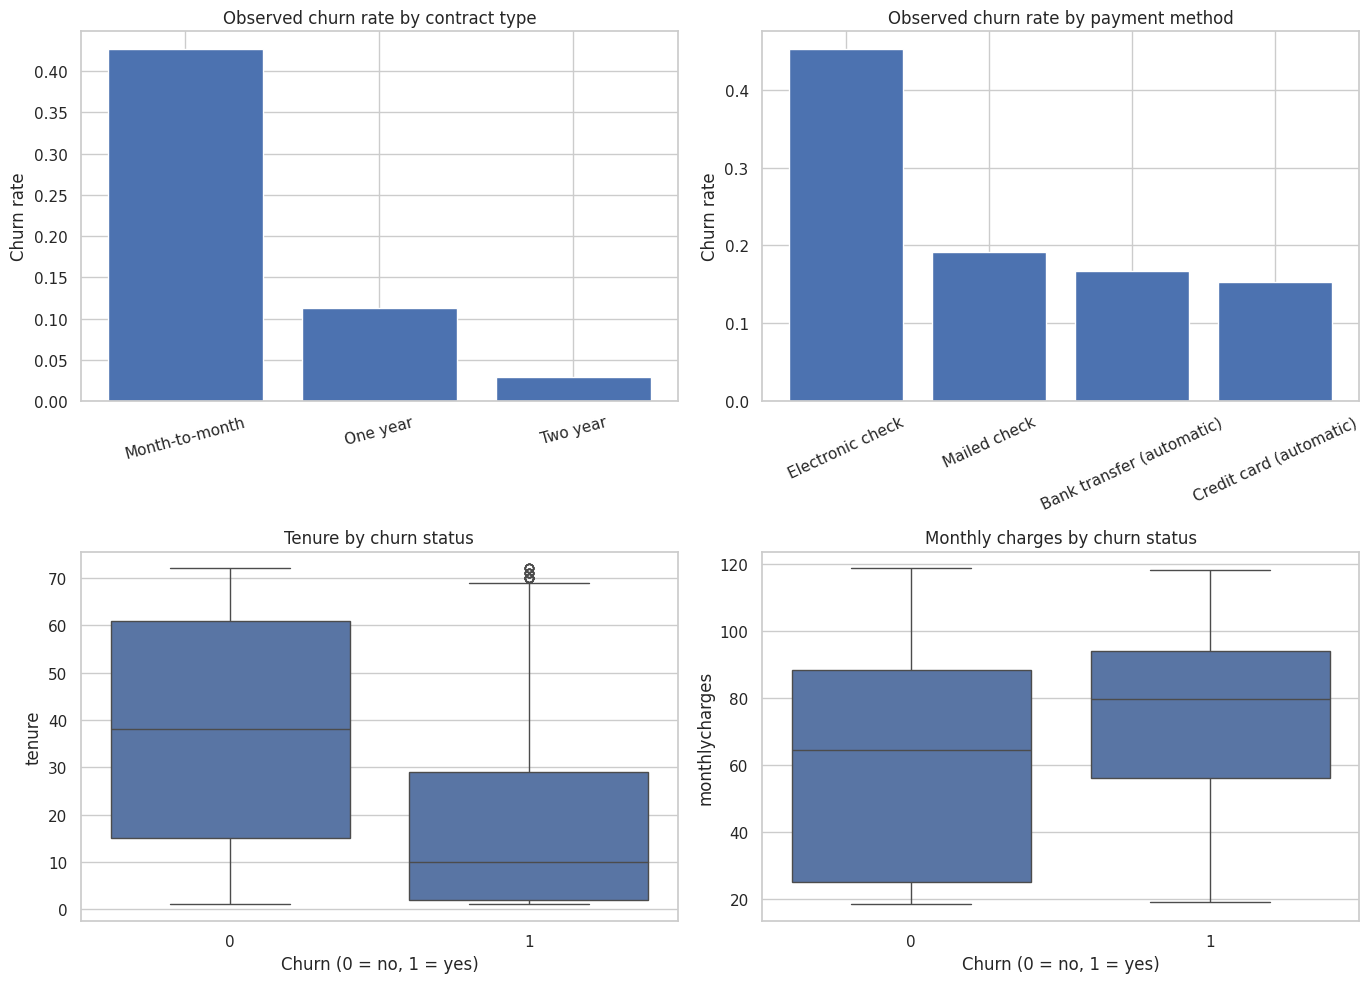

,customers,churn_rate
contract,,
Month-to-month,3875,0.427
One year,1472,0.113
Two year,1685,0.028


,customers,churn_rate
paymentmethod,,
Electronic check,2365,0.453
Mailed check,1604,0.192
Bank transfer (automatic),1542,0.167
Credit card (automatic),1521,0.153


In [4]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Churn rate by contract
contract_rate = df.groupby("contract", observed=False)["churn"].mean().sort_values(ascending=False)
axes[0, 0].bar(contract_rate.index.astype(str), contract_rate.values)
axes[0, 0].set_title("Observed churn rate by contract type")
axes[0, 0].set_ylabel("Churn rate")
axes[0, 0].tick_params(axis="x", rotation=15)

# Churn rate by payment method
payment_rate = df.groupby("paymentmethod", observed=False)["churn"].mean().sort_values(ascending=False)
axes[0, 1].bar(payment_rate.index.astype(str), payment_rate.values)
axes[0, 1].set_title("Observed churn rate by payment method")
axes[0, 1].set_ylabel("Churn rate")
axes[0, 1].tick_params(axis="x", rotation=25)

# Tenure distributions by churn status
sns.boxplot(data=df, x="churn", y="tenure", ax=axes[1, 0])
axes[1, 0].set_title("Tenure by churn status")
axes[1, 0].set_xlabel("Churn (0 = no, 1 = yes)")

# Monthly charges by churn status
sns.boxplot(data=df, x="churn", y="monthlycharges", ax=axes[1, 1])
axes[1, 1].set_title("Monthly charges by churn status")
axes[1, 1].set_xlabel("Churn (0 = no, 1 = yes)")

plt.tight_layout()
plt.show()

display(df.groupby("contract", observed=False)["churn"].agg(customers="size", churn_rate="mean").sort_values("churn_rate", ascending=False).round(3))
display(df.groupby("paymentmethod", observed=False)["churn"].agg(customers="size", churn_rate="mean").sort_values("churn_rate", ascending=False).round(3))

### Findings from the supplied dataset

- Observed churn is **42.7%** for month-to-month customers, compared with **11.3%** for one-year contracts and **2.8%** for two-year contracts.
- Churn is **45.3%** among customers using electronic checks; it is about **15.3%–16.7%** for the two automatic-payment categories.
- Median tenure is **10 months** among churners and **38 months** among non-churners. Median monthly charges are **79.65** for churners versus **64.45** for non-churners.

These are descriptive associations, not evidence that a contract or payment method causes churn. The group-size tables are included to help assess how much data supports each rate.

## 5. Numeric relationships (descriptive correlation)

A correlation heatmap can highlight redundant numeric features and broad linear associations. It is not a causal analysis, and binary-encoded categories can make correlation interpretation especially limited.

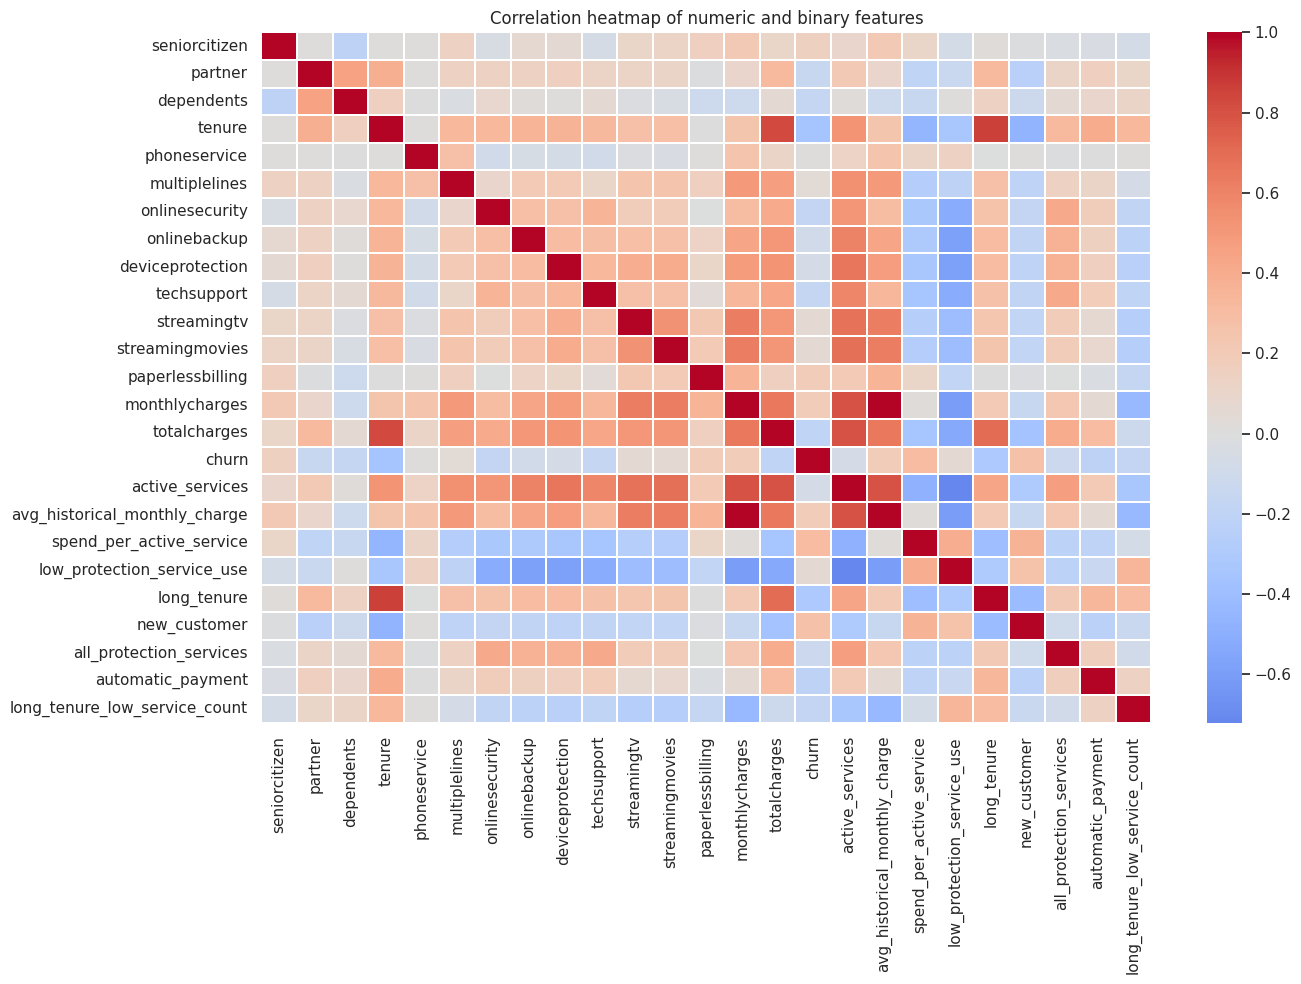

In [5]:
numeric_for_corr = df.select_dtypes(include=["number"]).copy()
plt.figure(figsize=(14, 10))
sns.heatmap(numeric_for_corr.corr(), cmap="coolwarm", center=0, linewidths=0.2)
plt.title("Correlation heatmap of numeric and binary features")
plt.tight_layout()
plt.show()

### Finding

Treat the heatmap as a diagnostic for overlapping information, not as a feature-selection algorithm by itself. For example, total charges, tenure, and monthly charges may be related by construction. A production analysis should examine multicollinearity and stability across validation samples.

## 6. Define a reproducible modeling dataset

The target is `churn`; customer ID is excluded. Categorical variables are one-hot encoded and numeric missing values are median-imputed. Standardization is applied to numeric features for Logistic Regression. All transformations live inside a scikit-learn pipeline so they are fit only on the training data, preventing test-set information from influencing preprocessing.

In [6]:
target = "churn"
X = df.drop(columns=[target]).copy()
y = df[target].astype(int)

# Avoid including both the raw payment method and its manually derived duplicate indicator.
# Keep the engineered indicator and drop raw payment method from this baseline feature set.
X = X.drop(columns=["paymentmethod"], errors="ignore")

categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = [c for c in X.columns if c not in categorical_features]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

print(f"Training rows: {len(X_train):,} | Test rows: {len(X_test):,}")
print(f"Predictor columns before encoding: {X.shape[1]}")
print(f"Numeric columns: {len(numeric_features)} | Categorical columns: {len(categorical_features)}")

Training rows: 5,625 | Test rows: 1,407
Predictor columns before encoding: 27
Numeric columns: 24 | Categorical columns: 3


## 7. Train and compare three baseline classifiers

- **Logistic Regression:** a relatively interpretable linear baseline.
- **Decision Tree:** captures nonlinear splits and interactions but can overfit.
- **Random Forest:** averages many trees to reduce the instability of a single tree.

`class_weight="balanced"` increases the relative penalty for errors on the less frequent class. This does not automatically make a model better; performance is assessed on the same held-out test set.

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=10, min_samples_leaf=5,
                                             class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
}

fitted_models = {}
rows = []
for name, estimator in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    fitted_models[name] = pipe
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, proba)
    })

results = pd.DataFrame(rows).sort_values("F1", ascending=False).reset_index(drop=True)
display(results.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Random Forest,0.756,0.529,0.765,0.625,0.834
1,Decision Tree,0.744,0.512,0.775,0.617,0.820
2,Logistic Regression,0.729,0.494,0.807,0.613,0.838


### Findings from the model comparison

With the fixed stratified split, Random Forest achieved the highest F1 (**0.625**) and precision (**0.529**) among these three baselines. Logistic Regression had the highest recall (**0.807**) and ROC-AUC (**0.838**), meaning it identified a larger share of churners at its default threshold and ranked cases slightly better overall. The Random Forest had F1 0.625, recall 0.765, and ROC-AUC 0.834. These differences are modest and specific to this split; they do not establish a universal winner.

## 8. Inspect the leading model's errors

For a transparent first pass, we inspect the model with the highest held-out F1. This is only a selection for error inspection—not a claim that it is the final production choice. The test set is used once for this baseline comparison; future hyperparameter tuning should use cross-validation inside the training set.

Model selected for error inspection: Random Forest
              precision    recall  f1-score   support

    No churn       0.90      0.75      0.82      1033
       Churn       0.53      0.76      0.63       374

    accuracy                           0.76      1407
   macro avg       0.71      0.76      0.72      1407
weighted avg       0.80      0.76      0.77      1407



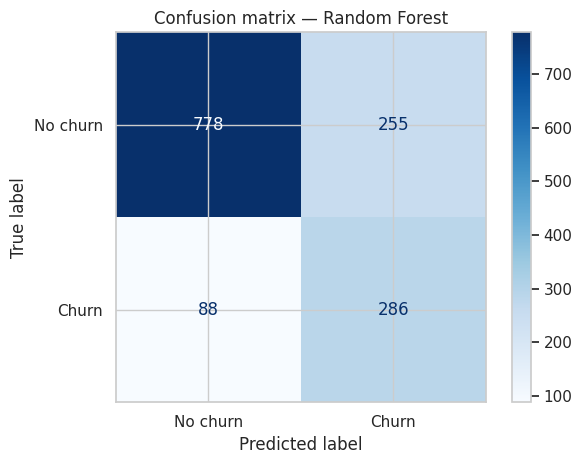

In [8]:
selected_name = results.loc[0, "Model"]
selected_model = fitted_models[selected_name]
y_pred = selected_model.predict(X_test)
y_prob = selected_model.predict_proba(X_test)[:, 1]

print("Model selected for error inspection:", selected_name)
print(classification_report(y_test, y_pred, target_names=["No churn", "Churn"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No churn", "Churn"], cmap="Blues")
plt.title(f"Confusion matrix — {selected_name}")
plt.tight_layout()
plt.show()

### Findings from the selected model's errors

The highest-F1 baseline is Random Forest. On the held-out set, it had about **0.53 precision** and **0.76 recall** for churn: it found roughly three-quarters of churners, but a substantial share of customers it flagged did not churn. This illustrates why the operating threshold should be chosen using retention campaign capacity and the relative costs of missed churners and unnecessary outreach, rather than accuracy alone.

## 9. Conclusions and limitations

This project demonstrates a reproducible churn-analysis workflow: data validation, interpretable feature engineering, exploratory group comparisons, pipeline-based preprocessing, baseline model comparison, and error analysis.

The most defensible findings are those visible in the generated group-rate tables and held-out metrics. These data are observational: associations between contract/service characteristics and churn do not establish causes. The current notebook is a baseline rather than a deployable retention system. Before using it operationally, add cross-validation, threshold/cost analysis, calibration, fairness checks, temporal validation, and monitoring.

**Lifetime value note:** the engineered spending variables are descriptive proxies. This notebook does not define a customer lifetime value outcome and should not be presented as a validated CLV model.